# Territory Vision — Global Solution CNN

Classificação de uso e cobertura do solo com CNNs próprias e quatro classes EuroSAT. A classificação não mede nem prevê escassez hídrica. Execute as células em ordem. Treinamento e download requerem tempo e internet.

In [ ]:
%pip install "tensorflow-cpu>=2.16,<2.21" "scikit-learn>=1.4,<2" "matplotlib>=3.8,<4" "gradio>=4,<6" pillow

## Dados, arquiteturas e treinamento

EuroSAT RGB oficial no Zenodo: https://zenodo.org/records/7711810. Amostra de 200 imagens por classe; divisão estratificada 60/20/20, normalização para [0,1]. Três CNNs próprias, sem modelos pré-treinados. Seleção pela validação, preservando teste para avaliação final. A separação aleatória não impede correlação espacial entre imagens próximas.

In [2]:
"""Experimentos EuroSAT: seleção exclusivamente por validação e teste final único."""
import json, os, random, zipfile, urllib.request
from pathlib import Path
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
SEED=42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError): pass
CLASSES=['Forest','Industrial','Residential','River']
ROOT=Path(os.environ.get('CNN_ROOT',Path.cwd())).resolve()
DATA=ROOT/'data'; OUT=ROOT/'outputs'; DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
archive=DATA/'EuroSAT.zip'
if not archive.exists():
    urllib.request.urlretrieve('https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1', archive)
folder=DATA/'2750'
if not folder.exists() and not (DATA/'EuroSAT_RGB').exists():
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            p=Path(info.filename)
            if p.is_absolute() or '..' in p.parts: raise ValueError('Caminho inseguro no arquivo zip')
        z.extractall(DATA)
if not folder.exists(): folder=DATA/'EuroSAT_RGB'
paths=[]; labels=[]
for label,name in enumerate(CLASSES):
    files=sorted((folder/name).glob('*.jpg'))
    if len(files)<200: raise RuntimeError(f'{name}: esperadas ao menos 200 imagens, encontradas {len(files)}')
    chosen=np.random.default_rng(SEED+label).choice(files,200,replace=False)
    paths.extend(map(str,chosen)); labels.extend([label]*200)
paths=np.array(paths); labels=np.array(labels)
trainval, test=train_test_split(np.arange(len(labels)),test_size=.2,stratify=labels,random_state=SEED)
train, val=train_test_split(trainval,test_size=.25,stratify=labels[trainval],random_state=SEED)
assert not (set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
# Converter uma vez mantém as mesmas imagens e normalização para os três experimentos.
def load(ids):
    imgs=[tf.keras.utils.img_to_array(tf.keras.utils.load_img(paths[i],target_size=(64,64)))/255.0 for i in ids]
    return np.asarray(imgs,dtype='float32'),labels[ids]
xtr,ytr=load(train); xv,yv=load(val); xt,yt=load(test)
(OUT/'split.json').write_text(json.dumps({k:[str(Path(paths[i]).relative_to(DATA)) for i in ids] for k,ids in [('train',train),('val',val),('test',test)]},indent=2))
configs=[
    {'name':'cnn_1','filters':[16,32],'dense':64,'dropout':0.0,'lr':0.001},
    {'name':'cnn_2','filters':[32,64],'dense':128,'dropout':0.25,'lr':0.001},
    {'name':'cnn_3','filters':[32,64,128],'dense':128,'dropout':0.35,'lr':0.0005},
]
def make_model(c):
    layers=[tf.keras.layers.Input((64,64,3))]
    for filters in c['filters']:
        layers.extend([tf.keras.layers.Conv2D(filters,3,padding='same',activation='relu'),tf.keras.layers.MaxPooling2D(2)])
    layers += [tf.keras.layers.Flatten(),tf.keras.layers.Dense(c['dense'],activation='relu')]
    if c['dropout']: layers.append(tf.keras.layers.Dropout(c['dropout']))
    layers.append(tf.keras.layers.Dense(4,activation='softmax'))
    model=tf.keras.Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(c['lr']),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return model
results=[]
for c in configs:
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    model=make_model(c)
    callback=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)
    history=model.fit(xtr,ytr,validation_data=(xv,yv),epochs=12,batch_size=32,callbacks=[callback],verbose=2)
    val_prob=model.predict(xv,verbose=0); val_pred=val_prob.argmax(axis=1)
    model.save(OUT/(c['name']+'.keras'))
    item={'config':c,'epochs_run':len(history.history['loss']),'val_accuracy':float(accuracy_score(yv,val_pred)),
          'val_report':classification_report(yv,val_pred,target_names=CLASSES,output_dict=True,zero_division=0),
          'val_confusion_matrix':confusion_matrix(yv,val_pred,labels=range(4)).tolist(),
          'history':{k:[float(x) for x in v] for k,v in history.history.items()},'parameters':model.count_params()}
    results.append(item)
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    for ax,key in zip(axes,['loss','accuracy']):
        ax.plot(history.history[key],label='treino'); ax.plot(history.history['val_'+key],label='validação'); ax.set_title(key); ax.legend(); ax.set_xlabel('época')
    fig.tight_layout(); fig.savefig(OUT/(c['name']+'_curvas.png'),dpi=150); plt.close(fig)
# Acurácia de validação decide; empate por menor loss de validação.
best=max(results,key=lambda x:(x['val_accuracy'],-min(x['history']['val_loss'])))
model=tf.keras.models.load_model(OUT/(best['config']['name']+'.keras'))
prob=model.predict(xt,verbose=0); pred=prob.argmax(axis=1)
summary={'classes':CLASSES,'seed':SEED,'counts':{'train':len(train),'validation':len(val),'test':len(test)},
         'selection':'maior acurácia de validação; desempate por menor perda de validação',
         'experiments':results,'best':best['config']['name'],
         'test_report':classification_report(yt,pred,target_names=CLASSES,output_dict=True,zero_division=0),
         'test_confusion_matrix':confusion_matrix(yt,pred,labels=range(4)).tolist()}
(OUT/'results.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))
model.save(OUT/'best.keras')
fig,ax=plt.subplots(figsize=(6,5)); cm=np.array(summary['test_confusion_matrix']); im=ax.imshow(cm,cmap='Blues'); fig.colorbar(im,ax=ax)
ax.set(xticks=range(4),yticks=range(4),xticklabels=CLASSES,yticklabels=CLASSES,xlabel='Previsto',ylabel='Real',title='Teste: matriz de confusão')
plt.setp(ax.get_xticklabels(),rotation=30,ha='right')
for i in range(4):
    for j in range(4): ax.text(j,i,str(cm[i,j]),ha='center',va='center')
fig.tight_layout(); fig.savefig(OUT/'matriz_teste.png',dpi=150); plt.close(fig)
print('Modelo selecionado:',summary['best']); print(classification_report(yt,pred,target_names=CLASSES,zero_division=0))


Epoch 1/12


15/15 - 10s - 635ms/step - accuracy: 0.3479 - loss: 1.2185 - val_accuracy: 0.7375 - val_loss: 1.0204


Epoch 2/12


15/15 - 4s - 233ms/step - accuracy: 0.6667 - loss: 0.9272 - val_accuracy: 0.6938 - val_loss: 0.7491


Epoch 3/12


15/15 - 3s - 219ms/step - accuracy: 0.7104 - loss: 0.6841 - val_accuracy: 0.6313 - val_loss: 0.7129


... (59 outputs left out)

15/15 - 4s - 275ms/step - accuracy: 0.8250 - loss: 0.4617 - val_accuracy: 0.8125 - val_loss: 0.4653


Epoch 10/12


15/15 - 5s - 346ms/step - accuracy: 0.8146 - loss: 0.4513 - val_accuracy: 0.8188 - val_loss: 0.4542


Modelo selecionado: cnn_2
              precision    recall  f1-score   support

      Forest       0.95      0.93      0.94        40
  Industrial       0.84      0.80      0.82        40
 Residential       0.78      0.72      0.75        40
       River       0.83      0.95      0.88        40

    accuracy                           0.85       160
   macro avg       0.85      0.85      0.85       160
weighted avg       0.85      0.85      0.85       160



## Comparação, métricas e análise

Compare acurácia de validação e teste, precisão, recall e F1 por classe. Examine a matriz de confusão e as curvas antes de justificar a escolha, o sobreajuste e as limitações. O teste não é usado para escolher a arquitetura.

cnn_1 acurácia validação: 0.85 parâmetros: 529700


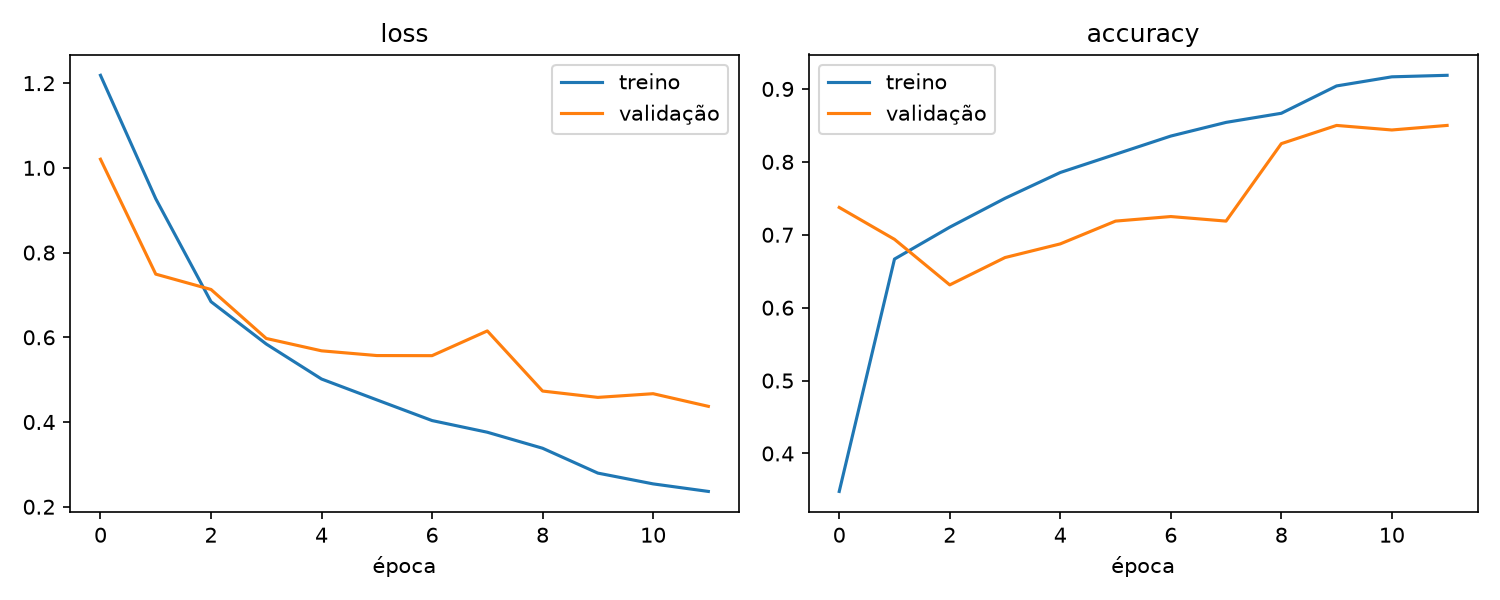

cnn_2 acurácia validação: 0.8688 parâmetros: 2117188


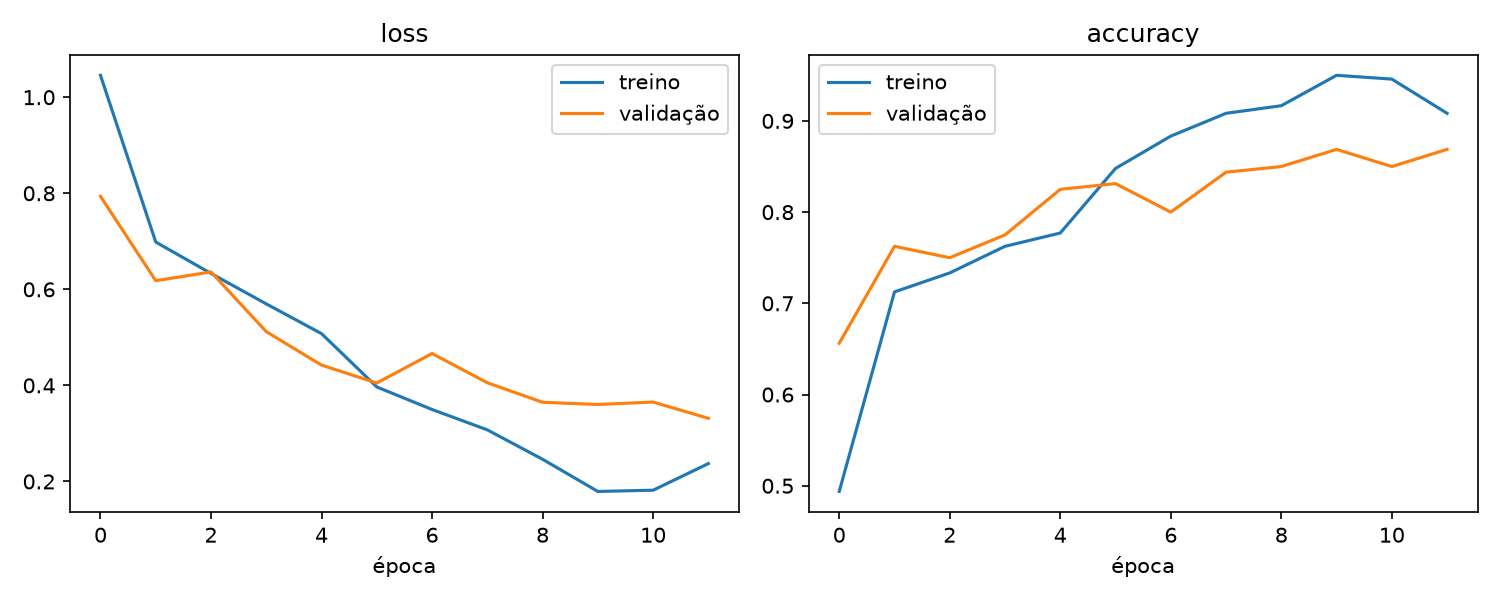

cnn_3 acurácia validação: 0.8313 parâmetros: 1142468


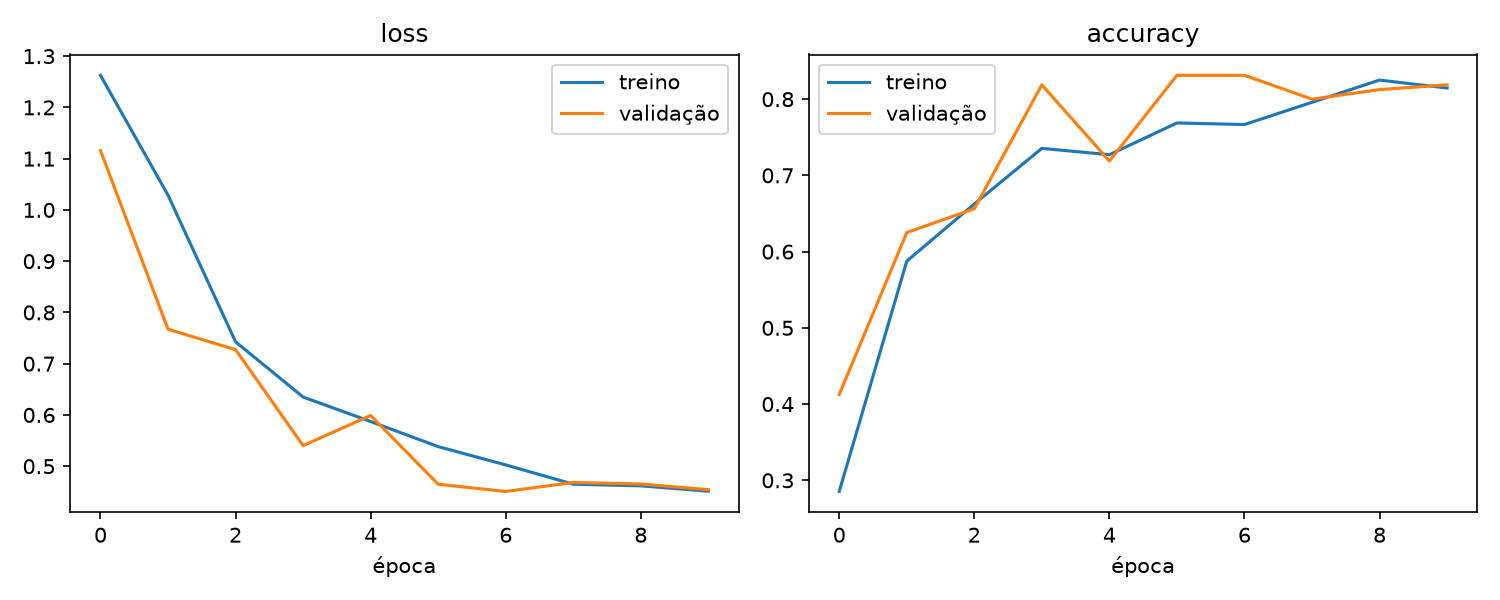

Selecionada: cnn_2
Relatório do teste: {
  "Forest": {
    "precision": 0.9487179487179487,
    "recall": 0.925,
    "f1-score": 0.9367088607594937,
    "support": 40.0
  },
  "Industrial": {
    "precision": 0.8421052631578947,
    "recall": 0.8,
    "f1-score": 0.8205128205128205,
    "support": 40.0
  },
  "Residential": {
    "precision": 0.7837837837837838,
    "recall": 0.725,
    "f1-score": 0.7532467532467533,
    "support": 40.0
  },
  "River": {
    "precision": 0.8260869565217391,
    "recall": 0.95,
    "f1-score": 0.8837209302325582,
    "support": 40.0
  },
  "accuracy": 0.85,
  "macro avg": {
    "precision": 0.8501734880453415,
    "recall": 0.8500000000000001,
    "f1-score": 0.8485473411879063,
    "support": 160.0
  },
  "weighted avg": {
    "precision": 0.8501734880453415,
    "recall": 0.85,
    "f1-score": 0.8485473411879063,
    "support": 160.0
  }
}


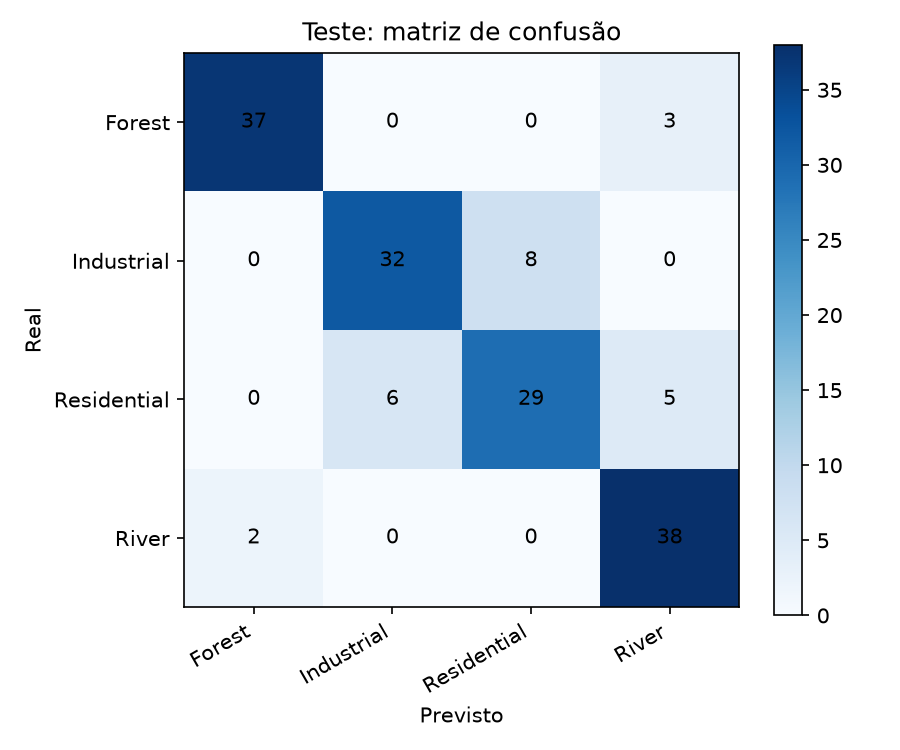

In [3]:
import json
from IPython.display import display, Image
r=json.loads((OUT/'results.json').read_text())
for e in r['experiments']:
    print(e['config']['name'], 'acurácia validação:', round(e['val_accuracy'],4), 'parâmetros:', e['parameters'])
    display(Image(filename=str(OUT/(e['config']['name']+'_curvas.png'))))
print('Selecionada:',r['best'])
print('Relatório do teste:', json.dumps(r['test_report'],ensure_ascii=False,indent=2))
display(Image(filename=str(OUT/'matriz_teste.png')))

## Aplicação web

Envie uma imagem semelhante às imagens de satélite RGB de 64×64 do EuroSAT. O resultado exibe probabilidades softmax para as quatro classes, que não são garantidamente calibradas.

In [ ]:
"""Aplicação Gradio para modelo final, sem alegar previsão hídrica."""
from pathlib import Path
import numpy as np
import tensorflow as tf
import gradio as gr

ROOT=Path(os.environ.get('CNN_ROOT', Path.cwd())).resolve()
MODEL=ROOT/'outputs'/'best.keras'
if not MODEL.exists(): raise SystemExit('Execute src/train.py antes de iniciar a aplicação: outputs/best.keras não existe.')
model=tf.keras.models.load_model(MODEL)
classes=['Forest','Industrial','Residential','River']
def classify(image):
    if image is None: raise gr.Error('Selecione uma imagem antes de classificar.')
    image=image.convert('RGB').resize((64,64))
    x=np.asarray(image,dtype='float32')[None,...]/255.0
    probabilities=model.predict(x,verbose=0)[0]
    return {label:float(probabilities[i]) for i,label in enumerate(classes)}
with gr.Blocks(title='Territory Vision') as app:
    gr.Markdown('# Territory Vision\nClassificação experimental de imagens semelhantes às do EuroSAT. O resultado não mede escassez hídrica nem substitui análise especializada.')
    inp=gr.Image(type='pil',label='Imagem de satélite')
    out=gr.Label(num_top_classes=4,label='Classe prevista e probabilidades')
    gr.Button('Classificar').click(classify,inp,out)
app.launch(inline=True, share=False)


## Uso de IA e autoria

IA generativa auxiliou na elaboração de código e documentação. A equipe deve conferir resultados, descrever efetivamente suas contribuições, justificar modificações e compreender treinamento, camadas e inferência. Complete nomes e RMs nos slides.